## Initial Spinup Analysis: 
Comparison of model output to forcing to ensure everything is working as expected.

Since the analysis here is monthly, I don't need to worry about Gregorian/Julian calendar conversions.

In [1]:
%matplotlib ipympl
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
import os

In [2]:
# Run configuration
snotel_site = 'Aneroid Lake #2'  #Use the Snotel name
spin_up = '100y'
forcings = 's00000000'
forcing_version = 'v0.4.4'  # Version of the forcing data
spinup_version = 'v1.0'
spinup_build_version = 'V0.1'
path_env = 'alpine' # 'desktop' or 'alpine'

In [3]:
# Configure environment
if path_env == 'desktop':
    output_path = 'C:/Users/clmbn/NMT_PhD/data/output' #desktop
    snotel_path = 'C:/Users/clmbn/NMT_PhD/data/snotel/' #desktop
    forcing_path = 'C:/Users/clmbn/NMT_PhD/data/forcing/' #desktop
elif path_env == 'alpine':
    output_path = r'/projects/ccox1@xsede.org/lm4px_modelling/output' #Alpine
    snotel_path = r'/projects/ccox1@xsede.org/data/snotel/'
    forcing_path = r'/projects/ccox1@xsede.org/lm4px_modelling/forcing/'
else:
    raise ValueError("Invalid path_env. Choose 'desktop' or 'alpine'.")

In [8]:
# Convert name for output paths
site = snotel_site.replace(' ','').lower()
site = site.replace('#','')
print(f'Output site: {site}')

Output site: aneroidlake2


Load forcing:
Forcing is 10 years of NLDAS data that is then looped for the spinup period.

In [9]:
forcing_10yr = xr.open_dataset(os.path.join(forcing_path, site, f'{site}_spinup{spinup_build_version}_s00000000_{forcing_version}.nc'))

In [10]:
forcing_10yr

<xarray.Dataset>
Dimensions:           (latitude: 1, longitude: 1, time: 87696)
Coordinates:
  * latitude          (latitude) float64 45.21
  * longitude         (longitude) float64 -117.2
  * time              (time) datetime64[ns] 1980-01-01 ... 1990-01-01T23:00:00
Data variables:
    Tair              (time, latitude, longitude) float64 ...
    Qair              (time, latitude, longitude) float64 ...
    Psurf             (time, latitude, longitude) float64 ...
    Rainf             (time, latitude, longitude) float64 ...
    Snowf             (time, latitude, longitude) float64 ...
    SWdown            (time, latitude, longitude) float64 ...
    LWdown            (time, latitude, longitude) float64 ...
    Wind              (time, latitude, longitude) float64 ...
    reference_height  (latitude, longitude) int64 ...
    canopy_height     (latitude, longitude) float64 ...

In [11]:
def get_spinup_forcing(forcing_ds: xr.Dataset, var_name: str) -> pd.Series:
    '''
    Extract a given variable (at a daily timestep) from the forcing dataset and loop it for the 100 year spinup period.
    Return a pandas Series with the looped data.
    '''
    # If 'precip' get sum of 'Rainf' and 'Snowf'
    if var_name == 'precip':
        forcing_ds = forcing_ds.assign(precip=forcing_ds['Rainf'] + forcing_ds['Snowf'])
    
    # Extract the variable data
    data = forcing_ds[var_name].isel(latitude=0, longitude=0).to_series()

    # Resample to daily frequency
    data_daily = data.resample('D').mean()

    # Loop the data for the spinup period
    # The model uses an interpolation algorithm to do the looping, but concatenating the data is sufficient for this purpose.
    # I need to leave off the last day of the data when concatenating because the spinup start and end on the same day.
    spinup_years = int(spin_up[:-1])  # Extract the number of years from the spin_up string
    looped = pd.concat([data_daily[:-1]] * int(spinup_years / 10), ignore_index=True)

    # Generate a new index that starts at the first day of the model run
    model_start_year = data_daily.index[-1].year - spinup_years
    model_start = data_daily.index[0].replace(year=model_start_year)
    looped.index = pd.date_range(start=model_start, periods=len(looped), freq='D')

    # Create date range accounting for Julian 1900 leap year if necessary
    # if model_start < pd.Timestamp('1900-03-01'):
    #     model_end = data_daily.index[-1] + pd.Timedelta(days=1)  # Add on a day to account for the leap year in 1900
    # else:
    #     model_end = data_daily.index[-1]
    # model_index = pd.date_range(start=model_start, end=model_end, freq='D')

    # Shift index by 12 hours to match model output
    looped.index = looped.index + pd.Timedelta(hours=12)

    looped.name = var_name

    return looped
    


Load diagnostics

In [12]:
output_folder = os.path.join(output_path,f'{site}/{site}_spinup_{spin_up}_{forcings}_{spinup_version}/history/')

In [13]:
# Find the land month file name in folder and open
land_month=None
for filename in os.listdir(output_folder):
    if filename.endswith(".land_month.nc"):
        land_month = xr.open_dataset(output_folder + filename)
if not land_month:
    print('Error: no land daily found')

In [14]:
# Create a dataframe whose index is the name of the variable and the columns are: dimensions, long_name, units
land_vars_df = pd.DataFrame({
    'dimensions': [land_month[var].dims for var in land_month.data_vars],
    'long_name': [land_month[var].attrs.get('long_name', '') for var in land_month.data_vars],
    'units': [land_month[var].attrs.get('units', '') for var in land_month.data_vars]
}, index=land_month.data_vars)

In [15]:
land_month

<xarray.Dataset>
Dimensions:                  (grid_index: 1, time: 1200, nv: 2, lon: 1,
                              lonb: 2, lat: 1, latb: 2, zfull_soil: 20,
                              zhalf_soil: 21, band: 2)
Coordinates:
  * grid_index               (grid_index) float64 0.0
  * time                     (time) object 1890-01-16 12:00:00 ... 1989-12-16...
  * nv                       (nv) float64 1.0 2.0
  * lon                      (lon) float64 -117.2
  * lonb                     (lonb) float64 -117.7 -116.7
  * lat                      (lat) float64 45.21
  * latb                     (latb) float64 44.71 45.71
  * zfull_soil               (zfull_soil) float64 0.01 0.04 0.08 ... 6.75 8.75
  * zhalf_soil               (zhalf_soil) float64 0.0 0.02 0.06 ... 6.0 7.5 10.0
  * band                     (band) float64 1.0 2.0
    geolon_t                 (grid_index) float32 ...
    geolat_t                 (grid_index) float32 ...
Data variables: (12/221)
    soil_ice                 (time, zfull_soil, grid_index) float32 ...
    soil_liq                 (time, zfull_soil, grid_index) float32 ...
    soil_psi                 (time, zfull_soil, grid_index) float32 ...
    soil_T                   (time, zfull_soil, grid_index) float32 ...
    soil_uptk                (time, zfull_soil, grid_index) float32 ...
    albedo_dif               (time, band, grid_index) float32 ...
    ...                       ...
    cwlitt_dmic_C_resp       (time, grid_index) float32 ...
    Ctot                     (time, grid_index) float32 ...
    average_T1               (time) datetime64[ns] ...
    average_T2               (time) datetime64[ns] ...
    average_DT               (time) timedelta64[ns] ...
    time_bnds                (time, nv) object ...
Attributes:
    filename:          land_month.nc
    title:             
    associated_files:  soil_area: land_static.nc land_area: land_static.nc
    grid_type:         regular
    grid_tile:         N/A

### Analysis: SW Radiation

In [16]:
forcing_SWdown = get_spinup_forcing(forcing_10yr, 'SWdown')
forcing_SWdown_month = forcing_SWdown.resample('MS').mean()

# Shift index forward 15 days to match the land month data
forcing_SWdown_month.index = forcing_SWdown_month.index + pd.DateOffset(days=15)

In [17]:
# Extract SW radiation components from land_daily
swdn_dir = land_month['swdn_dir'].isel(grid_index=0).to_dataframe()
swdn_dir = swdn_dir.reset_index().pivot(index='time', columns='band', values='swdn_dir')

swdn_diff = land_month['swdn_dif'].isel(grid_index=0).to_dataframe()
swdn_diff = swdn_diff.reset_index().pivot(index='time', columns='band', values='swdn_dif')

# Combine the direct and diffuse components
swdn_combined = pd.merge(swdn_dir, swdn_diff, left_index=True, right_index=True, suffixes=('_dir', '_dif'))

# Test
swdn_combined.head()

band,1.0_dir,2.0_dir,1.0_dif,2.0_dif
time,,,,
1890-01-16 12:00:00,20.868015,27.662252,12.790074,16.954285
1890-02-15 00:00:00,28.586124,37.893234,17.520527,23.224886
1890-03-16 12:00:00,44.557518,59.064617,27.309446,36.200893
1890-04-16 00:00:00,62.121719,82.347389,38.074600,50.470982
1890-05-16 12:00:00,70.943275,94.041092,43.481365,57.638088


In [18]:
swdn_combined['swdn_total'] = swdn_combined.sum(axis=1)

In [19]:
swdn_combined.index

Index([1890-01-16 12:00:00, 1890-02-15 00:00:00, 1890-03-16 12:00:00,
       1890-04-16 00:00:00, 1890-05-16 12:00:00, 1890-06-16 00:00:00,
       1890-07-16 12:00:00, 1890-08-16 12:00:00, 1890-09-16 00:00:00,
       1890-10-16 12:00:00,
       ...
       1989-03-16 12:00:00, 1989-04-16 00:00:00, 1989-05-16 12:00:00,
       1989-06-16 00:00:00, 1989-07-16 12:00:00, 1989-08-16 12:00:00,
       1989-09-16 00:00:00, 1989-10-16 12:00:00, 1989-11-16 00:00:00,
       1989-12-16 12:00:00],
      dtype='object', name='time', length=1200)

In [20]:
swdn_combined.index = pd.to_datetime([pd.Timestamp(x.strftime('%Y-%m-%d %H:%M:%S')) for x in swdn_combined.index])

Text(0.5, 1.0, 'SW Radiation Comparison')

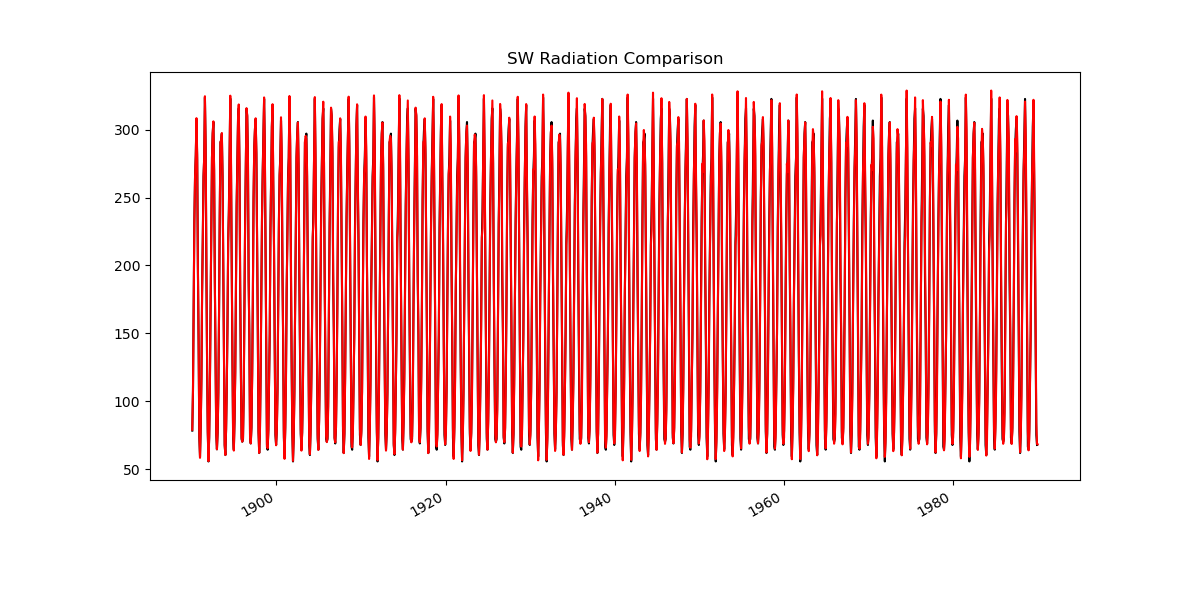

In [21]:
# Plotting the SW radiation components
plt.figure(figsize=(12, 6))
swdn_combined['swdn_total'].plot(label='Total SW Radiation', color='black')
forcing_SWdown_month.plot(label='Forcing SW Radiation', color='red')
plt.title('SW Radiation Comparison')

### Analysis: Vegetation

In [22]:
vegetation_data = land_month[['snow_depth','precip','Tgrnd','height','lai']].isel(grid_index=0).to_dataframe()
vegetation_data.index = vegetation_data.index.to_datetimeindex()

# Drop all extraneous columns
vegetation_data = vegetation_data[['snow_depth','precip','Tgrnd','height','lai']]

/tmp/ipykernel_1972522/2135545976.py:2: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'julian', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  vegetation_data.index = vegetation_data.index.to_datetimeindex()


Compare precip to verify that the forcing is correct.

In [23]:
forcing_precip = get_spinup_forcing(forcing_10yr, 'precip')
forcing_precip_month = forcing_precip.resample('MS').mean()

# Shift index forward 15 days to match the land month data
forcing_precip_month.index = forcing_precip_month.index + pd.DateOffset(days=15)

<AxesSubplot: >

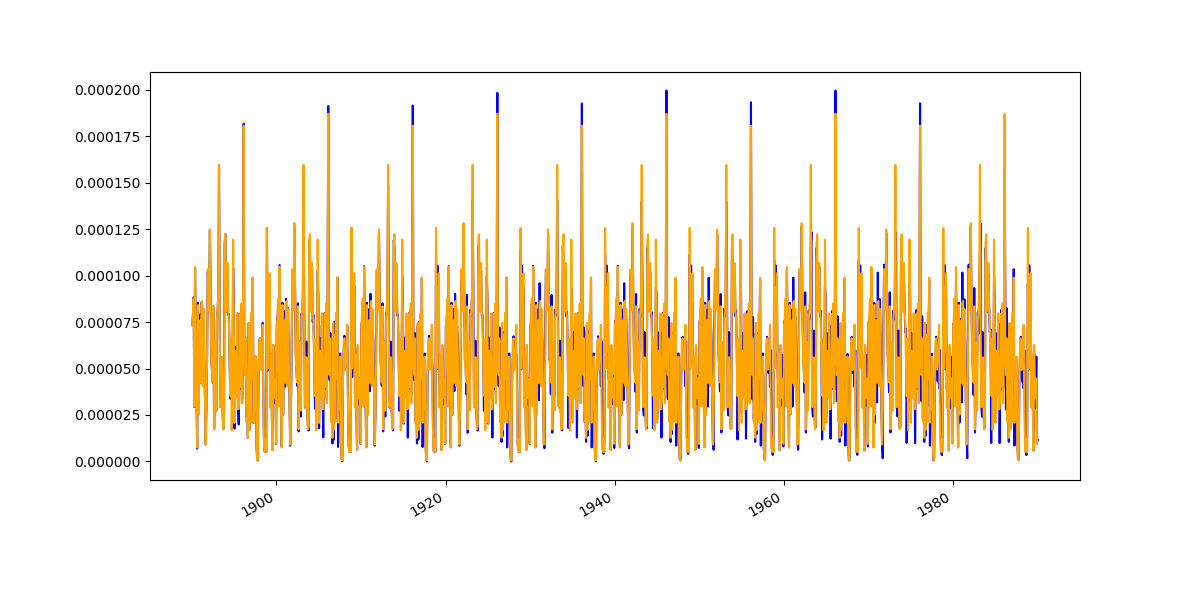

In [24]:
# Plot precip datasets on the same plot
fig, ax = plt.subplots(figsize=(12, 6))
forcing_precip_month.plot(ax=ax, label='Forcing Precipitation', color='blue')
vegetation_data['precip'].plot(ax=ax, label='Vegetation Precipitation', color='orange')

The two datasets should basically be the same, although the land_month data might be averaged differently with a julian calendar. At least they are quite similar.

array([<AxesSubplot: >, <AxesSubplot: >, <AxesSubplot: >, <AxesSubplot: >,
       <AxesSubplot: >], dtype=object)

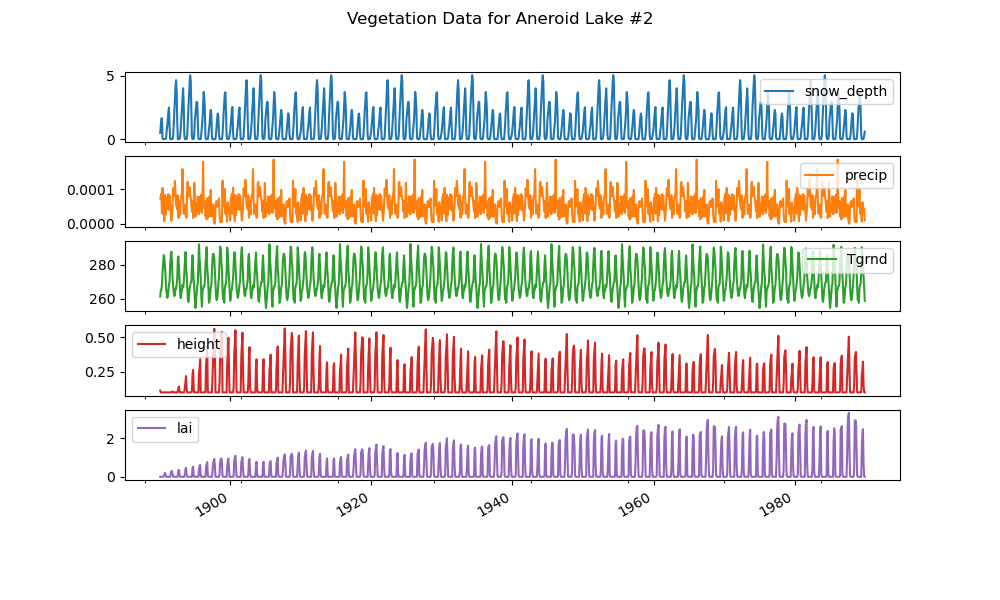

In [25]:
vegetation_data.plot(subplots=True, figsize=(10, 6), title='Vegetation Data for ' + snotel_site)

### Analysis: Soil

In [26]:
# Function for extracting soil data
def extract_soil_data(soil_var) -> pd.DataFrame:
    soil_data = land_month[[soil_var]].isel(grid_index=0).to_dataframe()
    soil_data_df = soil_data.reset_index().pivot(index='time', columns='zfull_soil', values=soil_var)
    soil_data_df.columns.name = 'Depth'
    soil_data_df.index = xr.CFTimeIndex(soil_data_df.index).to_datetimeindex()
    soil_data_df.columns = [f"{col:03.2f}" for col in soil_data_df.columns]
    return soil_data_df

In [27]:
# Extract the soil data at different depths
soil_T = extract_soil_data('soil_T')
soil_liq = extract_soil_data('soil_liq')
soil_ice = extract_soil_data('soil_ice')

/tmp/ipykernel_1972522/2036034610.py:6: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'julian', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  soil_data_df.index = xr.CFTimeIndex(soil_data_df.index).to_datetimeindex()
/tmp/ipykernel_1972522/2036034610.py:6: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'julian', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  soil_data_df.index = xr.CFTimeIndex(soil_data_df.index).to_datetimeindex()
/tmp/ipykernel_1972522/2036034610.py:6: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'julian', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operation

In [28]:
# Get air temperature from forcing data
Tair = get_spinup_forcing(forcing_10yr, 'Tair')
Tair_month = Tair.resample('MS').mean()

# Shift index forward 15 days to match the land month data
Tair_month.index = Tair_month.index + pd.DateOffset(days=15)

In [29]:
# Merge in ground surface temperature and air temperature
soil_T['Tgrnd'] = vegetation_data['Tgrnd']
#soil_T['Tair'] = Tair_month.to_numpy()

# Change soil_T values from Kelvin to Celsius
soil_T = soil_T - 273.15

# Add snow depth to soil_T dataframe
soil_T['snow_depth'] = vegetation_data['snow_depth']

array([<AxesSubplot: >, <AxesSubplot: >, <AxesSubplot: >, <AxesSubplot: >,
       <AxesSubplot: >], dtype=object)

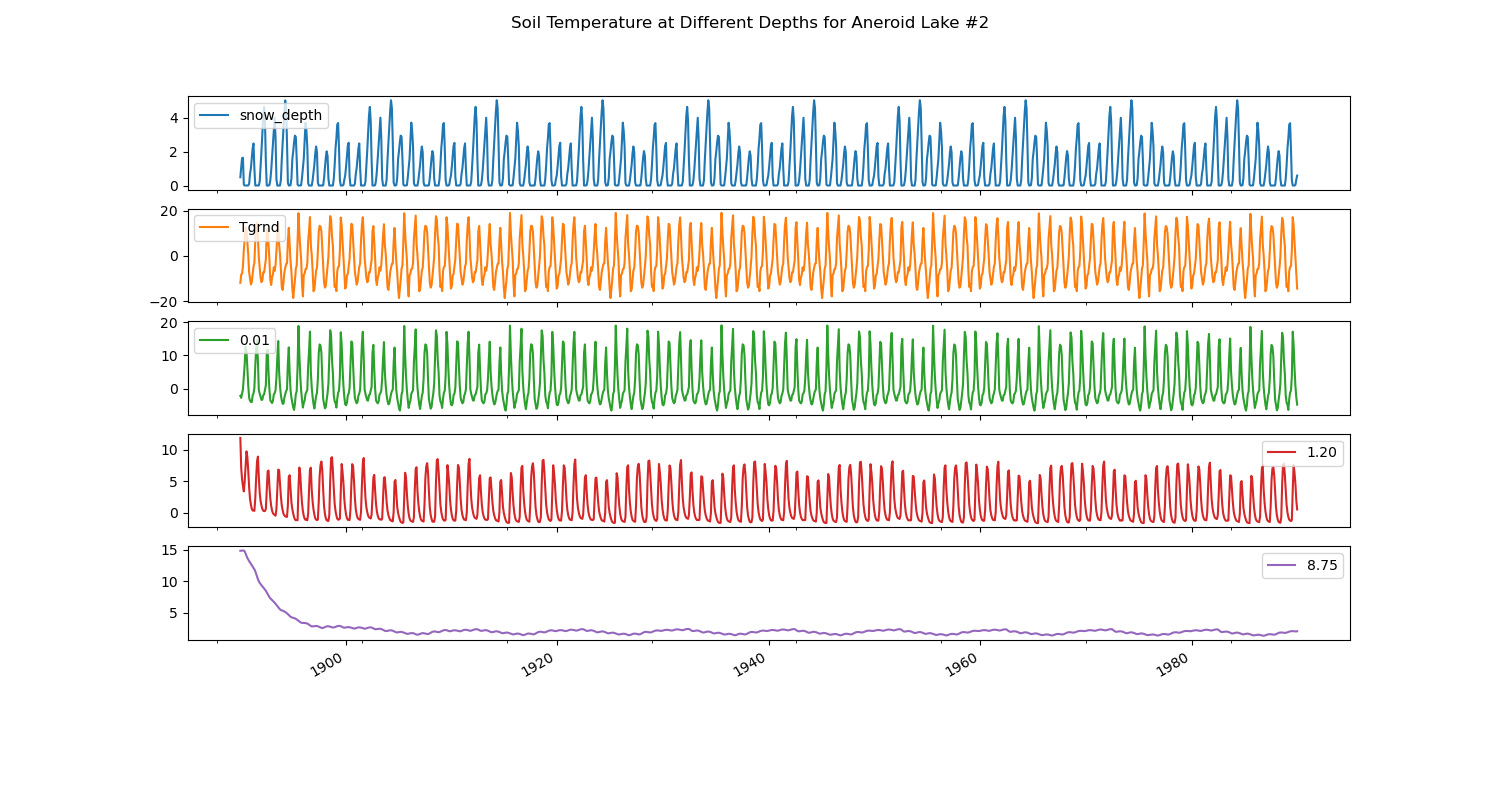

In [30]:
soil_T[['snow_depth','Tgrnd','0.01','1.20','8.75']].plot(subplots=True, figsize=(15, 8), title='Soil Temperature at Different Depths for ' + snotel_site)

array([<AxesSubplot: >, <AxesSubplot: >, <AxesSubplot: >, <AxesSubplot: >,
       <AxesSubplot: >, <AxesSubplot: >], dtype=object)

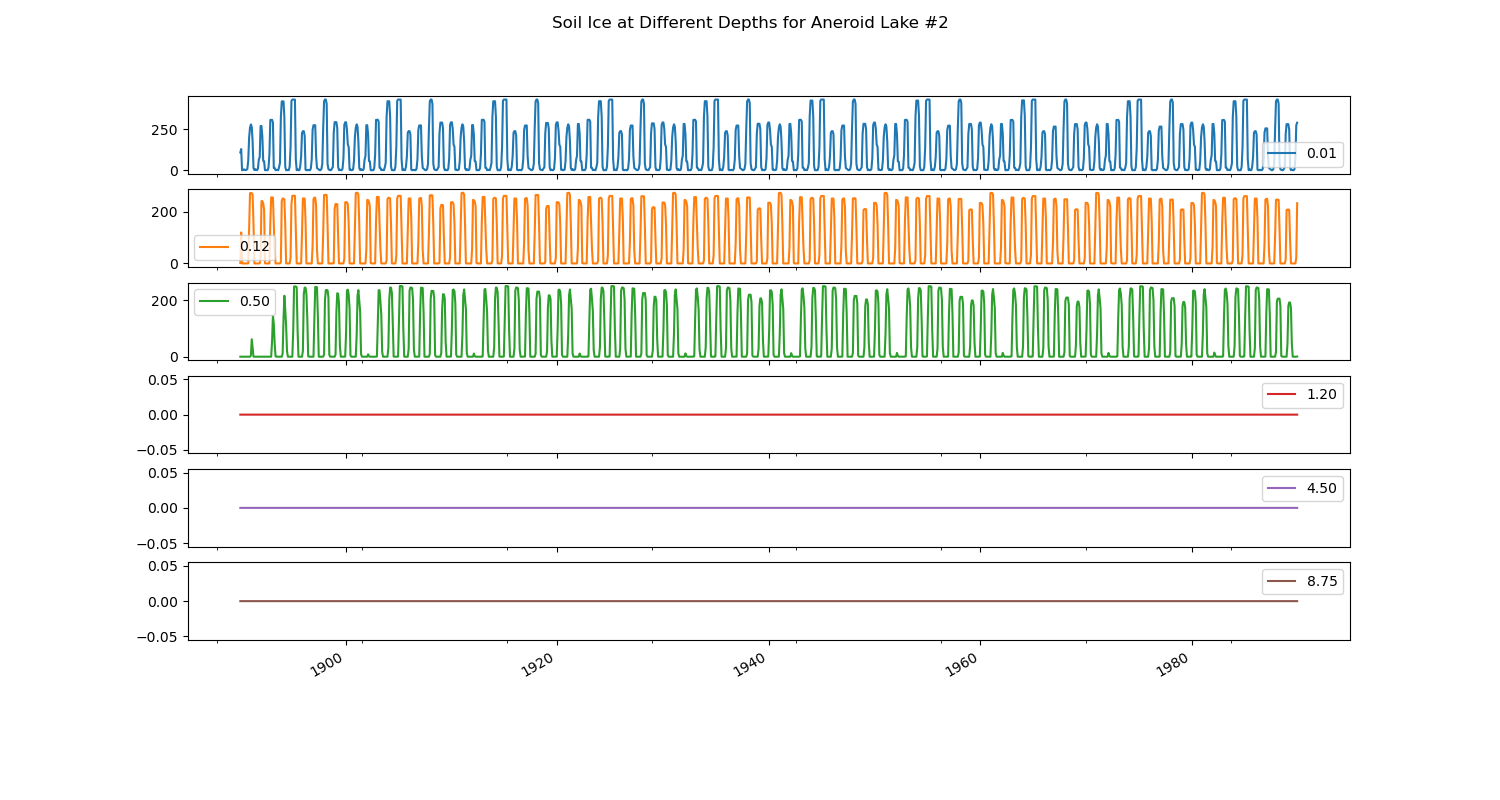

In [31]:
soil_ice[['0.01','0.12','0.50','1.20','4.50','8.75']].plot(subplots=True, figsize=(15, 8), title='Soil Ice at Different Depths for ' + snotel_site)

In [32]:
# Add precip to soil_liq dataframe
soil_liq['precip'] = vegetation_data['precip']

array([<AxesSubplot: >, <AxesSubplot: >, <AxesSubplot: >, <AxesSubplot: >,
       <AxesSubplot: >, <AxesSubplot: >, <AxesSubplot: >], dtype=object)

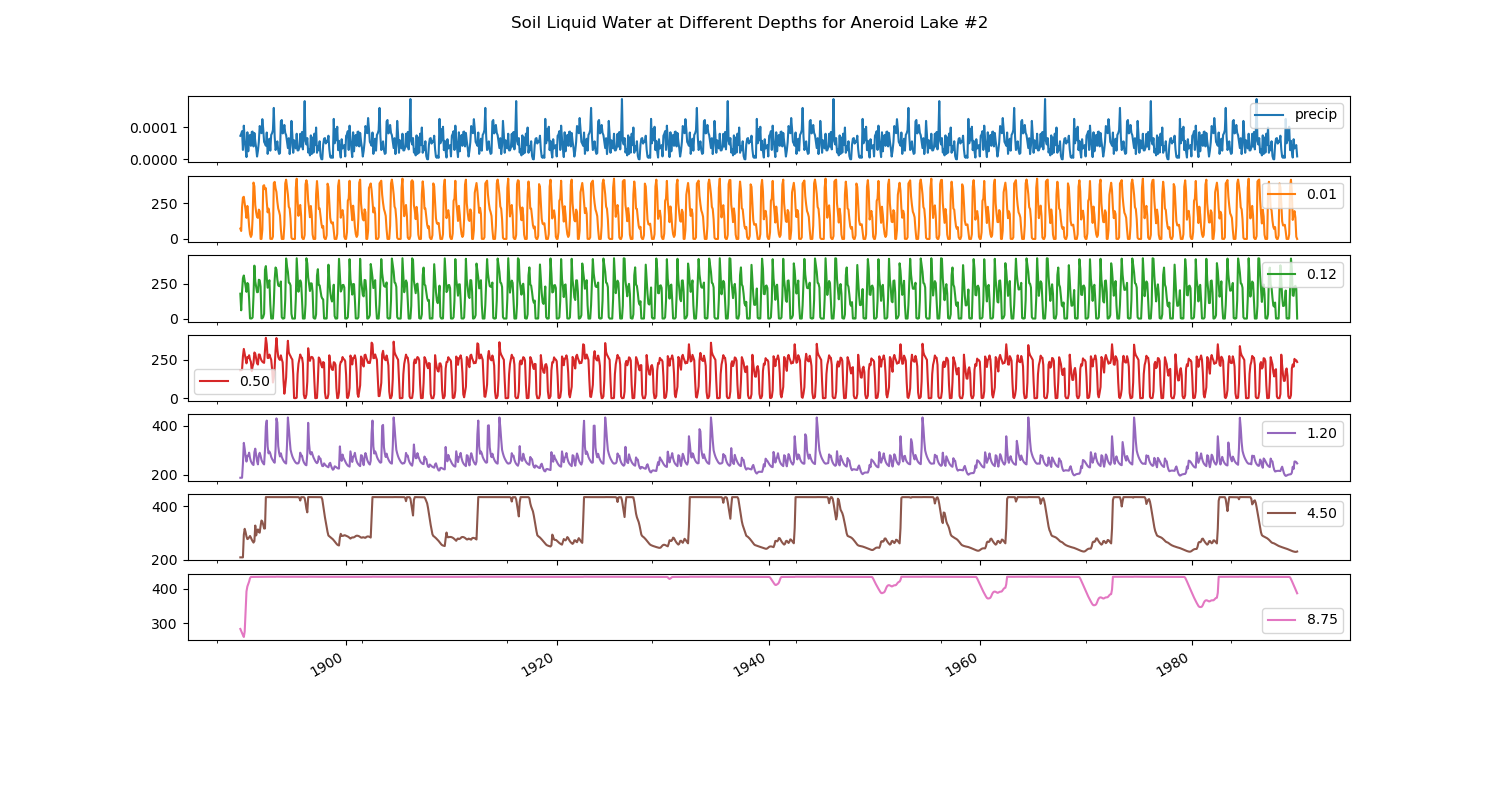

In [33]:
soil_liq[['precip','0.01','0.12','0.50','1.20','4.50','8.75']].plot(subplots=True, figsize=(15, 8), title='Soil Liquid Water at Different Depths for ' + snotel_site)